3.1 Install/import libraries



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

3.2 Load our CSV

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ecommerce_customer_churn_dataset (1).csv to ecommerce_customer_churn_dataset (1).csv


In [ ]:
df = pd.read_csv("ecommerce_customer_churn_dataset (1).csv")

In [ ]:
df.head()

,Customer_ID,Age,Gender,City,Signup_Date,Days_Since_Last_Purchase,Total_Orders,Average_Order_Value,Total_Spend,Discount_Usage_Pct,Return_Count,Support_Tickets,Average_Review_Score,Email_Open_Rate_Pct,App_Usage_Days_30D,Churn,Churn_Status
0,CUST10001,56,Female,Chennai,2025-12-01,125,8,723.07,5862.98,15.0,1,0,3.5,37.1,8,0,No
1,CUST10002,46,Male,Bengaluru,2024-01-01,39,6,1377.94,8402.70,16.2,1,0,2.6,20.8,12,0,No
2,CUST10003,32,Female,Hyderabad,2023-07-01,56,7,2969.39,21608.43,12.8,0,3,4.9,16.1,15,0,No
3,CUST10004,60,Female,Hyderabad,2025-12-01,29,6,3775.96,22241.95,5.1,0,0,4.9,71.9,28,0,No
4,CUST10005,25,Male,Hyderabad,2023-09-01,38,6,1875.88,11863.74,9.5,0,2,3.3,46.9,12,0,No


3.3 Check dataset size

In [ ]:
df.shape

(1200, 17)

3.4 Check column names

In [ ]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'City', 'Signup_Date',
       'Days_Since_Last_Purchase', 'Total_Orders', 'Average_Order_Value',
       'Total_Spend', 'Discount_Usage_Pct', 'Return_Count', 'Support_Tickets',
       'Average_Review_Score', 'Email_Open_Rate_Pct', 'App_Usage_Days_30D',
       'Churn', 'Churn_Status'],
      dtype='object')

3.5 Check data types

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               1200 non-null   object 
 1   Age                       1200 non-null   int64  
 2   Gender                    1200 non-null   object 
 3   City                      1200 non-null   object 
 4   Signup_Date               1200 non-null   object 
 5   Days_Since_Last_Purchase  1200 non-null   int64  
 6   Total_Orders              1200 non-null   int64  
 7   Average_Order_Value       1200 non-null   float64
 8   Total_Spend               1200 non-null   float64
 9   Discount_Usage_Pct        1200 non-null   float64
 10  Return_Count              1200 non-null   int64  
 11  Support_Tickets           1200 non-null   int64  
 12  Average_Review_Score      1200 non-null   float64
 13  Email_Open_Rate_Pct       1200 non-null   float64
 14  App_Usag

3.6 Check missing values

In [ ]:
df.isnull().sum()

,0
Customer_ID,0
Age,0
Gender,0
City,0
Signup_Date,0
Days_Since_Last_Purchase,0
Total_Orders,0
Average_Order_Value,0
Total_Spend,0
Discount_Usage_Pct,0


3.7 Check duplicate records

In [ ]:
df.duplicated().sum()

np.int64(0)

3.8 Basic statistics

In [ ]:
df.describe()

,Age,Days_Since_Last_Purchase,Total_Orders,Average_Order_Value,Total_Spend,Discount_Usage_Pct,Return_Count,Support_Tickets,Average_Review_Score,Email_Open_Rate_Pct,App_Usage_Days_30D,Churn
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,38.986667,69.903333,6.980000,1529.980050,10714.789700,12.002250,0.606667,1.614167,3.787500,57.741750,11.384167,0.019167
std,12.346059,47.400295,2.480873,717.749477,6452.902265,5.816472,0.791082,1.256960,0.763105,17.864003,6.663977,0.137168
min,18.000000,1.000000,1.000000,386.620000,1075.660000,0.000000,0.000000,0.000000,1.000000,5.000000,0.000000,0.000000
25%,28.000000,35.000000,5.000000,1021.490000,6046.555000,7.700000,0.000000,1.000000,3.300000,45.675000,6.000000,0.000000
50%,40.000000,59.000000,7.000000,1388.530000,9236.285000,12.100000,0.000000,1.000000,3.800000,57.700000,11.000000,0.000000
75%,50.000000,93.000000,9.000000,1901.507500,13879.052500,16.200000,1.000000,2.000000,4.400000,69.900000,16.000000,0.000000
max,60.000000,312.000000,16.000000,5223.890000,56095.930000,32.900000,5.000000,8.000000,5.000000,100.000000,30.000000,1.000000


STEP 4 — Churn Analysis in Python


4.1 Churn count

In [ ]:
df["Churn_Status"].value_counts()

,count
Churn_Status,
No,1177
Yes,23


4.2 Churn percentage

In [ ]:
df["Churn_Status"].value_counts(normalize=True) * 100

,proportion
Churn_Status,
No,98.083333
Yes,1.916667


4.3 Churn visualization

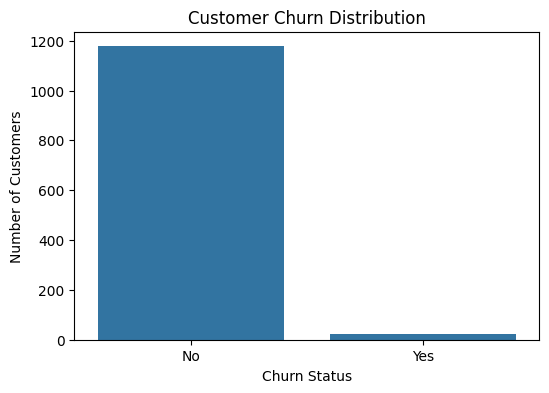

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Churn_Status")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

STEP 5 — Find What Causes Churn

5.1 Churn vs days since last purchase

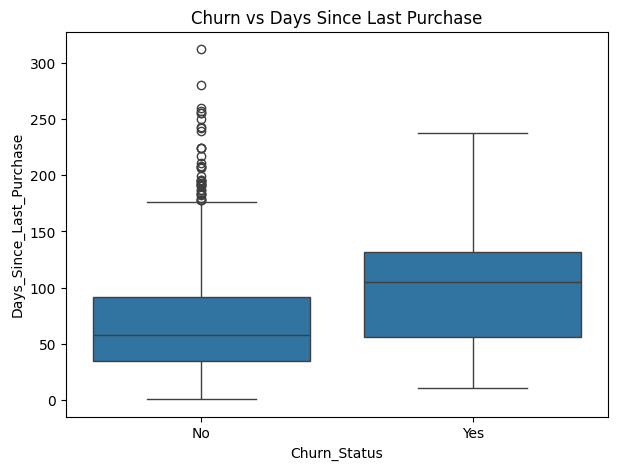

In [ ]:
plt.figure(figsize=(7,5))

sns.boxplot(data=df, x="Churn_Status",
            y="Days_Since_Last_Purchase")

plt.title("Churn vs Days Since Last Purchase")
plt.show()

5.2 Churn vs total orders

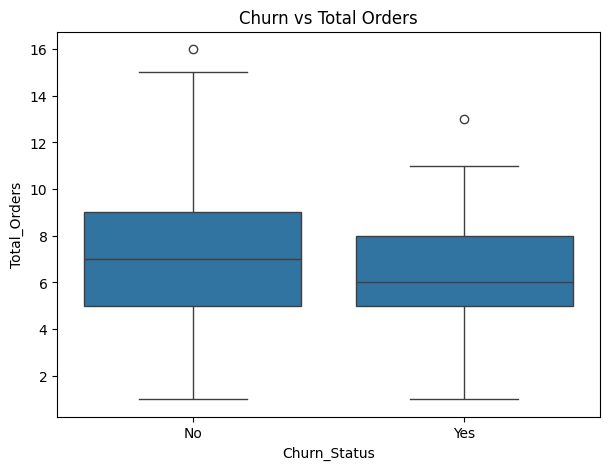

In [ ]:
plt.figure(figsize=(7,5))

sns.boxplot(data=df,
            x="Churn_Status",
            y="Total_Orders")

plt.title("Churn vs Total Orders")
plt.show()

5.3 Churn vs total spending

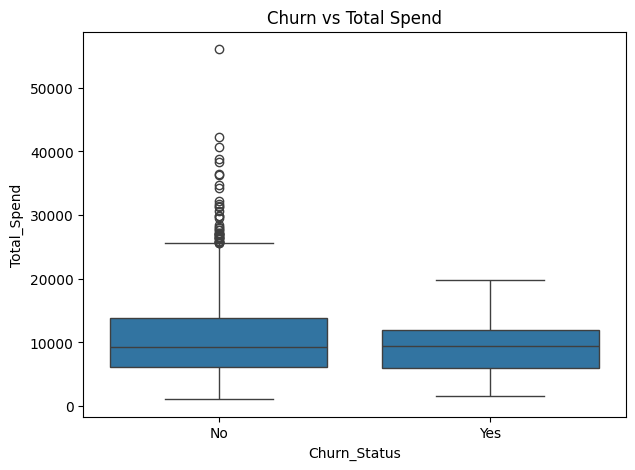

In [ ]:
plt.figure(figsize=(7,5))

sns.boxplot(data=df,
            x="Churn_Status",
            y="Total_Spend")

plt.title("Churn vs Total Spend")
plt.show()

5.4 Churn vs review score

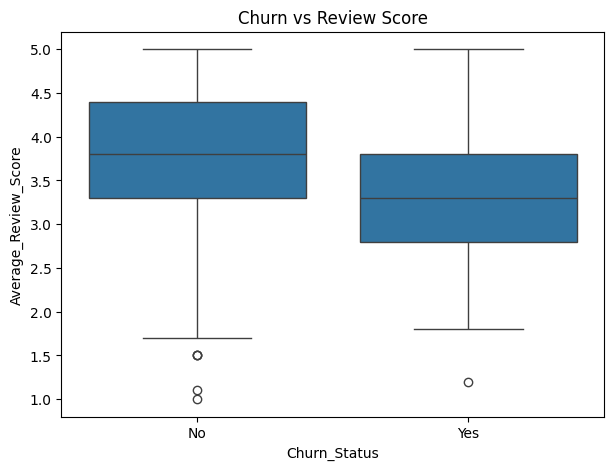

In [ ]:
plt.figure(figsize=(7,5))

sns.boxplot(data=df,
            x="Churn_Status",
            y="Average_Review_Score")

plt.title("Churn vs Review Score")
plt.show()

5.5 City-wise churn

In [ ]:
city_churn = df.groupby("City")["Churn"].mean().sort_values(ascending=False) * 100

print(city_churn)

City
Mumbai       3.125000
Ahmedabad    2.941176
Chennai      2.531646
Bengaluru    2.453988
Hyderabad    1.935484
Delhi        1.626016
Pune         0.704225
Kolkata      0.000000
Name: Churn, dtype: float64


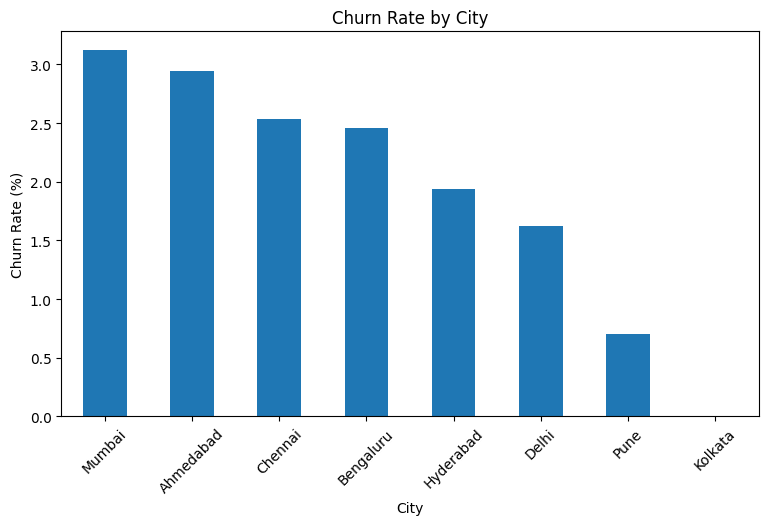

In [ ]:
plt.figure(figsize=(9,5))

city_churn.plot(kind="bar")

plt.title("Churn Rate by City")
plt.xlabel("City")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.show()

6. Correlation Analysis

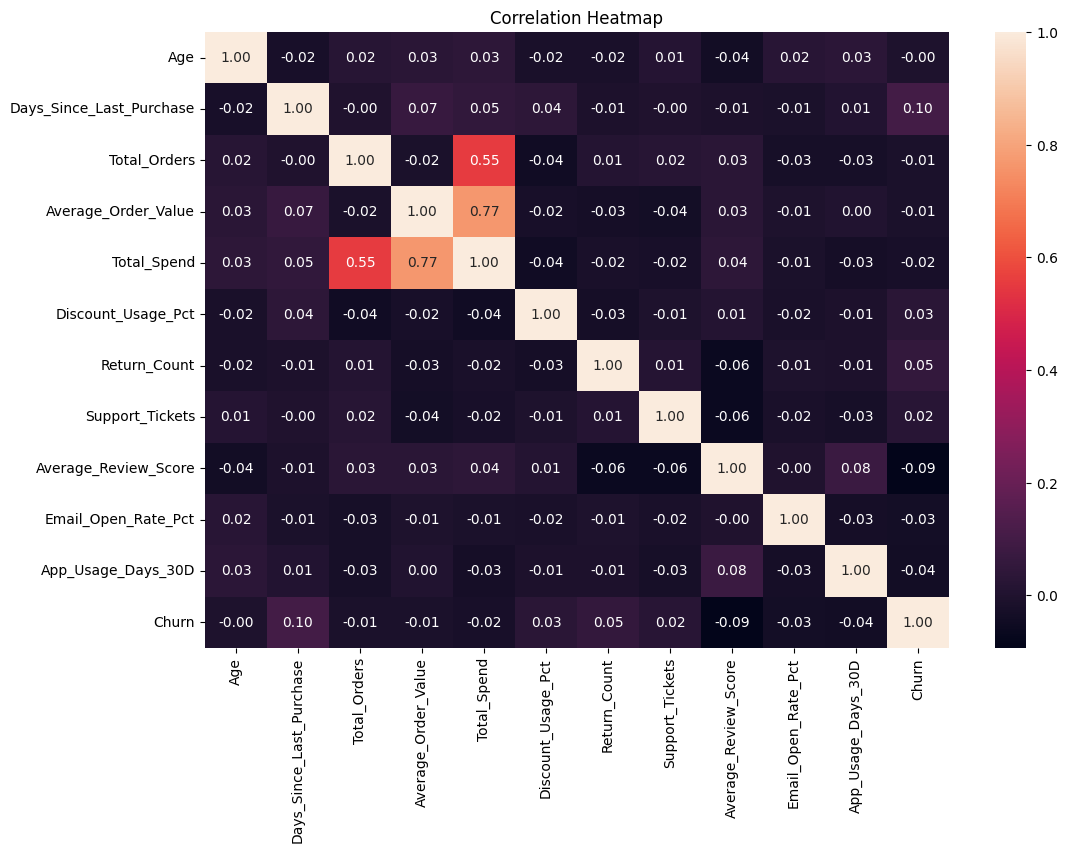

In [ ]:
numeric_cols = df.select_dtypes(include="number")

plt.figure(figsize=(12,8))

sns.heatmap(
    numeric_cols.corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

STEP 7 — Understand RFM

| RFM               | Meaning                         | Our dataset                |
| ----------------- | ------------------------------- | -------------------------- |
| **R — Recency**   | How recently customer purchased | `Days_Since_Last_Purchase` |
| **F — Frequency** | How often customer purchased    | `Total_Orders`             |
| **M — Monetary**  | How much customer spent         | `Total_Spend`              |


7.1 Create RFM DataFrame

In [ ]:
rfm = df[[
    "Customer_ID",
    "Days_Since_Last_Purchase",
    "Total_Orders",
    "Total_Spend"
]].copy()

In [ ]:
# Now rename the columns and check
rfm.rename(columns={
    "Days_Since_Last_Purchase": "Recency",
    "Total_Orders": "Frequency",
    "Total_Spend": "Monetary"
}, inplace=True)
rfm.head()

,Customer_ID,Recency,Frequency,Monetary
0,CUST10001,125,8,5862.98
1,CUST10002,39,6,8402.70
2,CUST10003,56,7,21608.43
3,CUST10004,29,6,22241.95
4,CUST10005,38,6,11863.74


7.2 Check RFM Statistics

In [ ]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,1200.000000,1200.000000,1200.000000
mean,69.903333,6.980000,10714.789700
std,47.400295,2.480873,6452.902265
min,1.000000,1.000000,1075.660000
25%,35.000000,5.000000,6046.555000
50%,59.000000,7.000000,9236.285000
75%,93.000000,9.000000,13879.052500
max,312.000000,16.000000,56095.930000


7.3 Create RFM Scores

7.3.1 Recency score

In [ ]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

7.3.2 Frequency score

In [ ]:
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

7.3.3 Monetary score

In [ ]:
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [ ]:
# check
rfm.head()

,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,CUST10001,125,8,5862.98,1,4,2
1,CUST10002,39,6,8402.70,4,2,3
2,CUST10003,56,7,21608.43,3,3,5
3,CUST10004,29,6,22241.95,5,2,5
4,CUST10005,38,6,11863.74,4,2,4


7.4 Create RFM Score

In [ ]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

7.5 Create Total RFM Score

In [ ]:
rfm["RFM_Total"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

8. Create Customer Segments

In [ ]:
def segment_customer(score):
    if score >= 13:
        return "Champions"
    elif score >= 10:
        return "Loyal Customers"
    elif score >= 8:
        return "Potential Loyalists"
    elif score >= 6:
        return "At Risk"
    else:
        return "Lost Customers"

rfm["Customer_Segment"] = rfm["RFM_Total"].apply(segment_customer)

In [ ]:
#check
rfm["Customer_Segment"].value_counts()

,count
Customer_Segment,
Loyal Customers,410
Potential Loyalists,270
At Risk,220
Lost Customers,162
Champions,138


9. See the Complete RFM Table

In [ ]:
rfm.head(20)

,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Customer_Segment
0,CUST10001,125,8,5862.98,1,4,2,142,7,At Risk
1,CUST10002,39,6,8402.70,4,2,3,423,9,Potential Loyalists
2,CUST10003,56,7,21608.43,3,3,5,335,11,Loyal Customers
3,CUST10004,29,6,22241.95,5,2,5,525,12,Loyal Customers
4,CUST10005,38,6,11863.74,4,2,4,424,10,Loyal Customers
5,CUST10006,18,10,7945.02,5,5,3,553,13,Champions
6,CUST10007,31,9,9674.68,5,4,3,543,12,Loyal Customers
7,CUST10008,75,9,20089.26,2,4,5,245,11,Loyal Customers
8,CUST10009,192,5,13246.65,1,1,4,114,6,At Risk
9,CUST10010,22,10,9909.32,5,5,3,553,13,Champions


10. Analyze Each Segment

10.1 Number of customers

In [ ]:
segment_count = rfm["Customer_Segment"].value_counts()

print(segment_count)

Customer_Segment
Loyal Customers        410
Potential Loyalists    270
At Risk                220
Lost Customers         162
Champions              138
Name: count, dtype: int64


10.2 Percentage of customers

In [ ]:
segment_percentage = (
    rfm["Customer_Segment"]
    .value_counts(normalize=True) * 100
).round(2)

print(segment_percentage)

Customer_Segment
Loyal Customers        34.17
Potential Loyalists    22.50
At Risk                18.33
Lost Customers         13.50
Champions              11.50
Name: proportion, dtype: float64


11. Segment Revenue

In [ ]:
segment_revenue = (
    rfm.groupby("Customer_Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

print(segment_revenue)

Customer_Segment
Loyal Customers        5552416.93
Champions              2524245.71
Potential Loyalists    2523028.69
At Risk                1499673.23
Lost Customers          758383.08
Name: Monetary, dtype: float64


12. Average Behavior by Segment

In [ ]:
segment_analysis = rfm.groupby("Customer_Segment").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean",
    "Customer_ID": "count"
}).round(2)

segment_analysis.rename(
    columns={"Customer_ID": "Customer_Count"},
    inplace=True
)

print(segment_analysis)

                     Recency  Frequency  Monetary  Customer_Count
Customer_Segment                                                 
At Risk                78.16       5.12   6816.70             220
Champions              31.83       9.86  18291.64             138
Lost Customers        108.46       4.13   4681.38             162
Loyal Customers        61.55       8.36  13542.48             410
Potential Loyalists    72.19       6.64   9344.55             270


13. Visualize RFM Segments

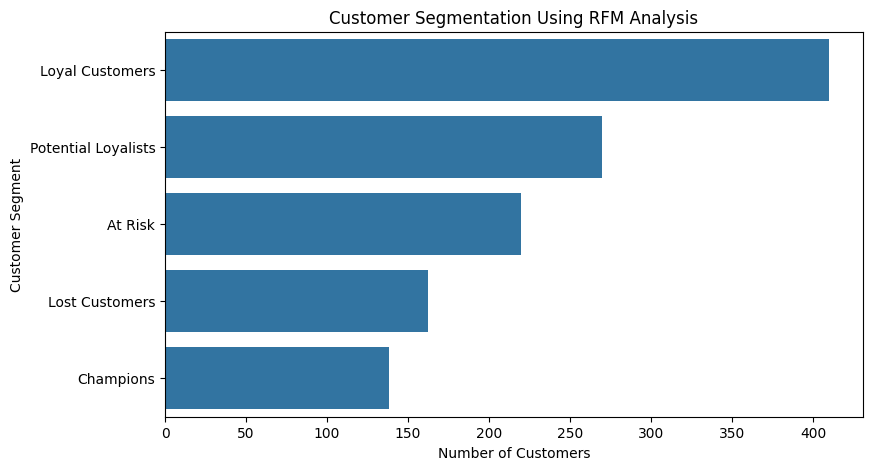

In [ ]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=rfm,
    y="Customer_Segment",
    order=rfm["Customer_Segment"].value_counts().index
)

plt.title("Customer Segmentation Using RFM Analysis")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.show()

14. Revenue by Segment

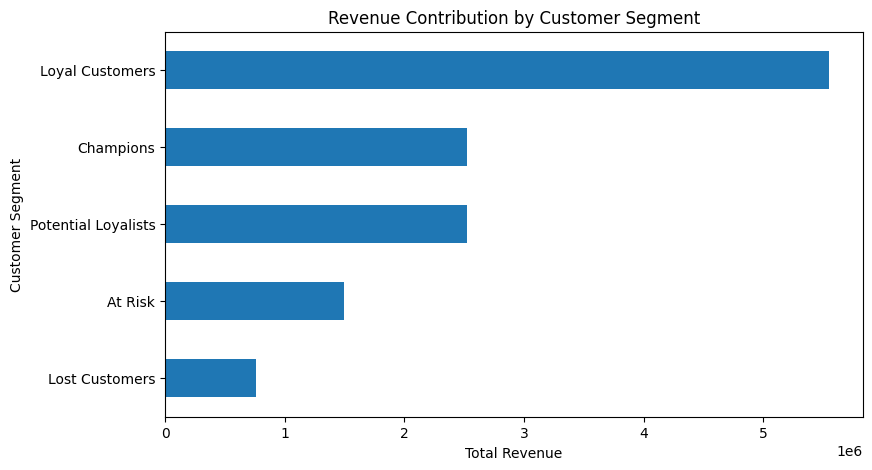

In [ ]:
plt.figure(figsize=(9,5))

segment_revenue.sort_values().plot(kind="barh")

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Segment")
plt.show()

15. Connect RFM with Churn

In [ ]:
rfm = rfm.merge(
    df[["Customer_ID", "Churn", "Churn_Status"]],
    on="Customer_ID",
    how="left"
)

In [ ]:
segment_churn = (
    rfm.groupby("Customer_Segment")["Churn"]
    .mean() * 100
)

segment_churn = segment_churn.round(2)

print(segment_churn)

Customer_Segment
At Risk                2.73
Champions              0.72
Lost Customers         3.09
Loyal Customers        1.22
Potential Loyalists    2.22
Name: Churn, dtype: float64


16. Find At-Risk Customers

In [ ]:
at_risk = rfm[
    rfm["Customer_Segment"] == "At Risk"
].sort_values(
    "Monetary",
    ascending=False
)

at_risk.head(20)

,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Customer_Segment,Churn,Churn_Status
93,CUST10094,113,5,16444.77,1,1,5,115,7,At Risk,0,No
248,CUST10249,206,5,15679.79,1,1,5,115,7,At Risk,0,No
192,CUST10193,112,6,15059.60,1,2,4,124,7,At Risk,0,No
1190,CUST11191,156,4,14204.51,1,1,4,114,6,At Risk,0,No
313,CUST10314,139,5,14140.04,1,1,4,114,6,At Risk,0,No
234,CUST10235,144,6,13888.02,1,2,4,124,7,At Risk,0,No
1116,CUST11117,112,5,13793.58,1,2,4,124,7,At Risk,0,No
941,CUST10942,79,4,13575.44,2,1,4,214,7,At Risk,0,No
915,CUST10916,108,5,13527.88,1,2,4,124,7,At Risk,0,No
642,CUST10643,107,5,13518.70,1,2,4,124,7,At Risk,0,No


17. Find High-Value Churned Customers

In [ ]:
high_value_churned = rfm[
    (rfm["Monetary"] >= rfm["Monetary"].median()) &
    (rfm["Churn"] == 1)
].sort_values(
    "Monetary",
    ascending=False
)

high_value_churned.head(20)

,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Customer_Segment,Churn,Churn_Status
417,CUST10418,109,13,19723.90,1,5,5,155,11,Loyal Customers,1,Yes
1005,CUST11006,49,8,18810.60,3,4,5,345,12,Loyal Customers,1,Yes
337,CUST10338,30,8,18698.59,5,4,5,545,14,Champions,1,Yes
110,CUST10111,162,10,15474.57,1,5,5,155,11,Loyal Customers,1,Yes
832,CUST10833,129,8,14410.34,1,4,4,144,9,Potential Loyalists,1,Yes
659,CUST10660,225,9,13301.58,1,4,4,144,9,Potential Loyalists,1,Yes
1053,CUST11054,112,6,10495.04,1,3,3,133,7,At Risk,1,Yes
999,CUST11000,51,6,10461.05,3,3,3,333,9,Potential Loyalists,1,Yes
215,CUST10216,87,4,10395.12,2,1,3,213,6,At Risk,1,Yes
167,CUST10168,49,8,10069.19,3,4,3,343,10,Loyal Customers,1,Yes


18. Export RFM Results

In [ ]:
rfm.to_csv(
    "customer_rfm_segmentation.csv",
    index=False
)

NameError: name 'rfm' is not defined

Export RFM results to CSV

In [ ]:
# Export RFM results to CSV
rfm.to_csv("customer_rfm_segmentation.csv", index=False)

print("RFM file created successfully!")

NameError: name 'rfm' is not defined